左侧图片数: 9
右侧图片数: 9
可直接对比的共同文件数: 9


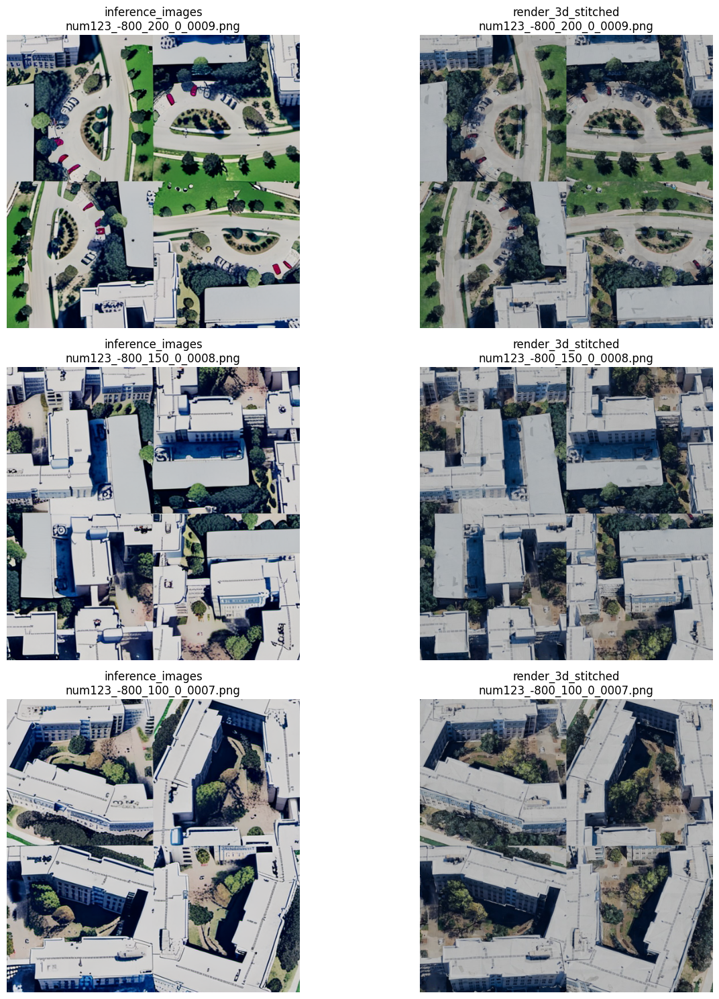

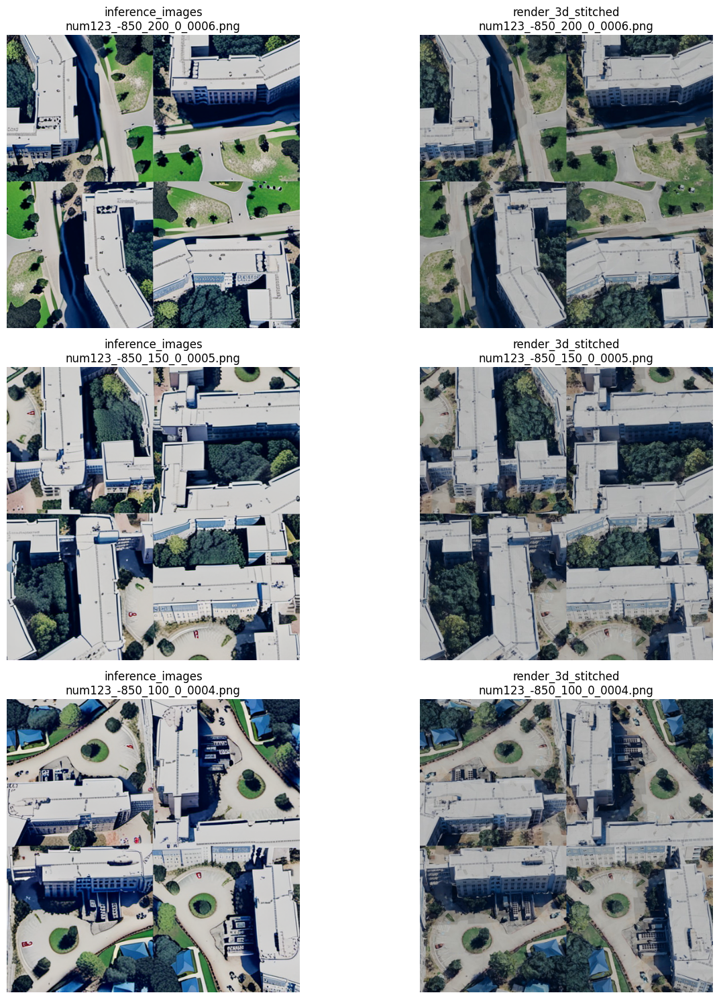

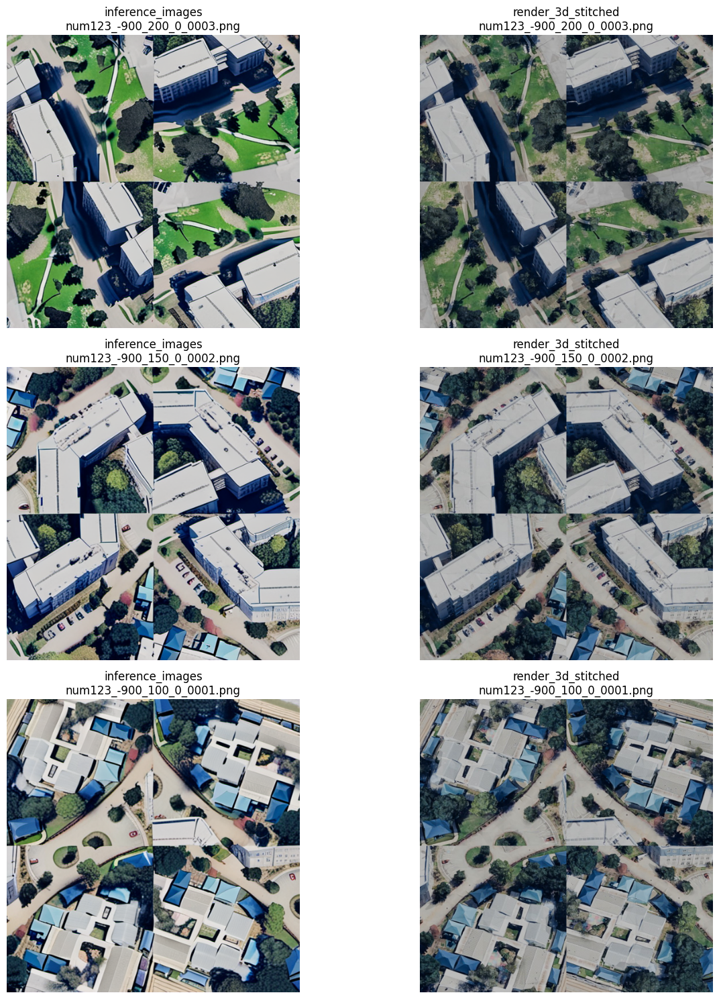

In [4]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# 要比较的两个目录
left_dir = Path('/home/viplab/liukejia/project/result/inference_images')
right_dir = Path('/home/viplab/liukejia/project/result/render_3d_stitched')

# 取两边都存在的文件名，避免缺图时报错
left_files = {p.name: p for p in left_dir.glob('*') if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}}
right_files = {p.name: p for p in right_dir.glob('*') if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}}
common_names = sorted(left_files.keys() & right_files.keys())

print(f'左侧图片数: {len(left_files)}')
print(f'右侧图片数: {len(right_files)}')
print(f'可直接对比的共同文件数: {len(common_names)}')

if not common_names:
    raise ValueError('两个目录中没有同名图片可对比。')

# 每页显示多少组
pairs_per_page = 3

for start in range(0, len(common_names), pairs_per_page):
    batch = common_names[start:start + pairs_per_page][::-1]
    fig, axes = plt.subplots(len(batch), 2, figsize=(14, 5 * len(batch)))
    if len(batch) == 1:
        axes = [axes]

    for row, name in enumerate(batch):
        img_left = Image.open(left_files[name]).convert('RGB')
        img_right = Image.open(right_files[name]).convert('RGB')

        ax_l, ax_r = axes[row]
        ax_l.imshow(img_left)
        ax_l.set_title(f'inference_images\n{name}')
        ax_l.axis('off')

        ax_r.imshow(img_right)
        ax_r.set_title(f'render_3d_stitched\n{name}')
        ax_r.axis('off')

    plt.tight_layout()
    plt.show()


Common coordinates: 9


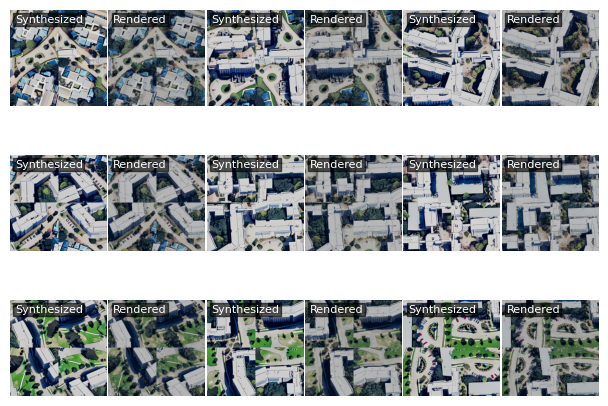

In [8]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import re

# 目录路径
left_dir = Path('/home/viplab/liukejia/project/result/inference_images')
right_dir = Path('/home/viplab/liukejia/project/result/render_3d_stitched')

extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}

def parse_coordinates(filename: str):
    """Parse (x, y) from filename format 'num123_-800_100_0_0007.png'"""
    stem = Path(filename).stem
    parts = stem.split('_')
    if len(parts) >= 3:
        try:
            x = int(parts[1])
            y = int(parts[2])
            return x, y
        except ValueError:
            pass
    match = re.search(r'(-?\d+)_(-?\d+)', filename)
    if match:
        return int(match.group(1)), int(match.group(2))
    return None, None

# Load images
left_dict = {}
right_dict = {}
for p in left_dir.glob('*'):
    if p.suffix.lower() in extensions:
        x, y = parse_coordinates(p.name)
        if x is not None:
            left_dict[(x, y)] = p
for p in right_dir.glob('*'):
    if p.suffix.lower() in extensions:
        x, y = parse_coordinates(p.name)
        if x is not None:
            right_dict[(x, y)] = p

common_coords = sorted(set(left_dict.keys()) & set(right_dict.keys()))
print(f'Common coordinates: {len(common_coords)}')
if not common_coords:
    raise ValueError('No matching image pairs found.')

# Grid layout
xs = sorted({c[0] for c in common_coords})
ys = sorted({c[1] for c in common_coords})
grid_x = len(xs)
grid_y = len(ys)

fig, axes = plt.subplots(grid_y, grid_x * 2,
                         figsize=(2 * grid_x, 1.5 * grid_y),
                         squeeze=False)

for ax in axes.flat:
    ax.axis('off')

x_to_idx = {x: i for i, x in enumerate(xs)}
y_to_idx = {y: i for i, y in enumerate(ys)}

for (x, y), path_left in left_dict.items():
    if (x, y) not in right_dict:
        continue
    row = y_to_idx[y]
    col_left = 2 * x_to_idx[x]
    col_right = col_left + 1

    # Ours (left)
    img_left = Image.open(path_left).convert('RGB')
    # GT (right)
    img_right = Image.open(right_dict[(x, y)]).convert('RGB')
    axes[row, col_left].imshow(img_left)
    axes[row, col_right].imshow(img_right)
    # 在循环内添加标签
    axes[row, col_left].text(0.05, 0.95, 'Synthesized', transform=axes[row, col_left].transAxes,
                            fontsize=8, color='white', ha='left', va='top',
                            bbox=dict(facecolor='black', alpha=0.6, pad=1))
    axes[row, col_right].text(0.05, 0.95, 'Rendered', transform=axes[row, col_right].transAxes,
                            fontsize=8, color='white', ha='left', va='top',
                            bbox=dict(facecolor='black', alpha=0.6, pad=1))

plt.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)
plt.show()

In [29]:
import os
import re
import numpy as np
import matplotlib
matplotlib.use('Agg')  # 无头后端
import matplotlib.pyplot as plt
from pathlib import Path
import trimesh
from PIL import Image
import io

# ========== 配置 ==========
PRED_DIR = Path("/home/viplab/liukejia/project/result/reconstruct_pred_scale")
GT_DIR   = Path("/home/viplab/liukejia/project/result/reconstruct_gt_scale")
OUT_DIR  = Path("/home/viplab/liukejia/project/result/rendered_comparison")
OUT_DIR.mkdir(exist_ok=True, parents=True)

IMG_SIZE = (512, 512)          # 输出图像尺寸 (width, height)
CAM_ELEV = 30                  # 俯仰角（度）
CAM_AZIM = -45                 # 方位角（度）
CAM_DIST = 2.0                 # 相机距离
POINT_SIZE = 1                 # 点大小（matplotlib 的 s 参数）
SAMPLE_LIMIT = 50000           # 点云采样上限

def parse_coords(filename):
    parts = Path(filename).stem.split('_')
    if len(parts) >= 3:
        try:
            return int(parts[1]), int(parts[2])
        except:
            pass
    return None

def load_points_from_glb(glb_path, sample_limit=SAMPLE_LIMIT):
    obj = trimesh.load(glb_path)
    points_list = []
    def collect(item):
        if isinstance(item, trimesh.Scene):
            for geom in item.geometry.values():
                collect(geom)
        elif isinstance(item, trimesh.PointCloud):
            if len(item.vertices) > 0:
                points_list.append(item.vertices)
        elif isinstance(item, trimesh.Trimesh):
            if len(item.vertices) > 0:
                points_list.append(item.vertices)
    collect(obj)
    if not points_list:
        return np.empty((0,3))
    all_pts = np.vstack(points_list)
    if len(all_pts) > sample_limit:
        idx = np.random.choice(len(all_pts), sample_limit, replace=False)
        all_pts = all_pts[idx]
    return all_pts

def normalize_points(points):
    if len(points) == 0:
        return points
    center = points.mean(axis=0)
    points_centered = points - center
    max_radius = np.linalg.norm(points_centered, axis=1).max()
    if max_radius > 0:
        points_centered /= max_radius
    return points_centered

def project_points(points, elev, azim, dist, img_size):
    """投影到像素坐标，返回 (u, v, depth) 有效点的数组"""
    if len(points) == 0:
        return np.array([]), np.array([]), np.array([])
    elev_rad = np.radians(elev)
    azim_rad = np.radians(azim)
    cx = dist * np.cos(elev_rad) * np.cos(azim_rad)
    cy = dist * np.cos(elev_rad) * np.sin(azim_rad)
    cz = dist * np.sin(elev_rad)
    forward = -np.array([cx, cy, cz])
    forward = forward / np.linalg.norm(forward)
    world_up = np.array([0, 1, 0])
    right = np.cross(world_up, forward)
    right = right / np.linalg.norm(right)
    up = np.cross(forward, right)
    R = np.vstack([right, up, forward])
    points_cam = points - np.array([cx, cy, cz])
    points_cam = points_cam @ R.T
    fov_rad = np.radians(45)
    focal = 1.0 / np.tan(fov_rad/2)
    x_proj = points_cam[:,0] * focal / points_cam[:,2]
    y_proj = points_cam[:,1] * focal / points_cam[:,2]
    width, height = img_size
    u = (x_proj + 1.0) * 0.5 * width
    v = (1.0 - (y_proj + 1.0) * 0.5) * height
    valid = (points_cam[:,2] > 0.01) & (u >= 0) & (u < width) & (v >= 0) & (v < height)
    return u[valid], v[valid], points_cam[valid, 2]

def render_points_to_image(points, img_size, elev, azim, dist, point_size=1):
    """手动渲染点云到 numpy 图像（无 matplotlib figure 抓取）"""
    u, v, depth = project_points(points, elev, azim, dist, img_size)
    if len(u) == 0:
        return np.ones((img_size[1], img_size[0], 3), dtype=np.uint8) * 240
    
    # 按深度排序（远到近）
    order = np.argsort(depth)[::-1]
    u = u[order].astype(int)
    v = v[order].astype(int)
    
    # 创建白色背景
    img = np.ones((img_size[1], img_size[0], 3), dtype=np.uint8) * 255
    # 颜色映射：根据深度使用蓝->红渐变
    norm_depth = (depth[order] - depth.min()) / (depth.max() - depth.min() + 1e-6)
    colors = plt.cm.jet(norm_depth)[:, :3]  # (N,3) 范围 0-1
    colors = (colors * 255).astype(np.uint8)
    
    # 绘制点（简单正方形块）
    half = point_size // 2
    for ui, vi, col in zip(u, v, colors):
        for dy in range(-half, half+1):
            for dx in range(-half, half+1):
                x = ui + dx
                y = vi + dy
                if 0 <= x < img_size[0] and 0 <= y < img_size[1]:
                    img[y, x] = col
    return img

def main():
    # 收集文件
    preds = {}
    gts = {}
    for p in PRED_DIR.glob("*.glb"):
        c = parse_coords(p.name)
        if c: preds[c] = p
    for p in GT_DIR.glob("*.glb"):
        c = parse_coords(p.name)
        if c: gts[c] = p

    common = sorted(set(preds.keys()) & set(gts.keys()))
    print(f"找到 {len(common)} 对共同坐标")
    if not common:
        raise ValueError("无共同文件")

    xs = sorted({c[0] for c in common})
    ys = sorted({c[1] for c in common})
    nx, ny = len(xs), len(ys)
    fig, axes = plt.subplots(ny, nx*2, figsize=(2*nx, 1.5*ny), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    plt.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)

    x2i = {x:i for i,x in enumerate(xs)}
    y2i = {y:i for i,y in enumerate(ys)}

    for (x,y) in common:
        row = y2i[y]
        col_left = 2 * x2i[x]
        col_right = col_left + 1
        print(f"\n处理坐标 ({x},{y})")

        # Predicted
        try:
            points = load_points_from_glb(preds[(x,y)])
            points = normalize_points(points)
            img = render_points_to_image(points, IMG_SIZE, CAM_ELEV, CAM_AZIM, CAM_DIST, POINT_SIZE)
            axes[row, col_left].imshow(img)
            axes[row, col_left].text(0.05, 0.95, 'Predicted', transform=axes[row, col_left].transAxes,
                                     fontsize=8, color='white', ha='left', va='top',
                                     bbox=dict(facecolor='black', alpha=0.5, pad=1))
        except Exception as e:
            print(f"  Predicted error: {e}")
            axes[row, col_left].text(0.5, 0.5, 'Render Error', ha='center', va='center')

        # Ground Truth
        try:
            points = load_points_from_glb(gts[(x,y)])
            points = normalize_points(points)
            img = render_points_to_image(points, IMG_SIZE, CAM_ELEV, CAM_AZIM, CAM_DIST, POINT_SIZE)
            axes[row, col_right].imshow(img)
            axes[row, col_right].text(0.05, 0.95, 'Ground Truth', transform=axes[row, col_right].transAxes,
                                      fontsize=8, color='white', ha='left', va='top',
                                      bbox=dict(facecolor='black', alpha=0.5, pad=1))
        except Exception as e:
            print(f"  GT error: {e}")
            axes[row, col_right].text(0.5, 0.5, 'Render Error', ha='center', va='center')

    out_png = OUT_DIR / "3d_comparison.png"
    out_pdf = OUT_DIR / "3d_comparison.pdf"
    plt.savefig(out_png, dpi=150, bbox_inches='tight')
    plt.savefig(out_pdf, bbox_inches='tight')
    print(f"\n对比图已保存至 {OUT_DIR}")
    plt.close()

if __name__ == "__main__":
    main()

找到 9 对共同坐标

处理坐标 (-900,100)

处理坐标 (-900,150)

处理坐标 (-900,200)

处理坐标 (-850,100)

处理坐标 (-850,150)

处理坐标 (-850,200)

处理坐标 (-800,100)

处理坐标 (-800,150)

处理坐标 (-800,200)

对比图已保存至 /home/viplab/liukejia/project/result/rendered_comparison


In [51]:
import os
import re
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path
import trimesh

# ========== 配置 ==========
PRED_DIR = Path("/home/viplab/liukejia/project/result/reconstruct_pred_scale")
GT_DIR   = Path("/home/viplab/liukejia/project/result/reconstruct_gt_scale")
OUT_DIR  = Path("/home/viplab/liukejia/project/result/rendered_comparison")
OUT_DIR.mkdir(exist_ok=True, parents=True)

IMG_SIZE = (512, 512)
CAM_ELEV = 30
CAM_AZIM = -45
CAM_DIST = 0.5
CAM_ZOOM = 0.8

# 参数：稀疏点云使用手动投影（大方块），密集点云使用 matplotlib scatter（圆形抗锯齿）
SPARSE_THRESHOLD = 25000       # 点数低于此值视为稀疏
POINT_SIZE_SPARSE = 3          # 手动投影时的方块半宽（最终边长 = 2*size+1）
POINT_SIZE_DENSE = 1           # scatter 的点大小（面积参数）

def parse_coords(filename):
    parts = Path(filename).stem.split('_')
    if len(parts) >= 3:
        try:
            return int(parts[1]), int(parts[2])
        except:
            pass
    return None

def load_points_and_colors(glb_path):
    """返回 (points, colors)，colors 为 (N,3) uint8 或 None"""
    obj = trimesh.load(glb_path)
    points_list = []
    colors_list = []
    def collect(item):
        if isinstance(item, trimesh.Scene):
            for geom in item.geometry.values():
                collect(geom)
        elif isinstance(item, trimesh.PointCloud):
            if len(item.vertices) > 0:
                points_list.append(item.vertices)
                if item.colors is not None:
                    colors = item.colors
                    if colors.shape[1] == 4:
                        colors = colors[:, :3]
                    if colors.max() <= 1.0:
                        colors = (colors * 255).astype(np.uint8)
                    colors_list.append(colors)
                else:
                    colors_list.append(None)
        elif isinstance(item, trimesh.Trimesh):
            if len(item.vertices) > 0:
                points_list.append(item.vertices)
                # 尝试读取顶点颜色
                if hasattr(item.visual, 'vertex_colors') and item.visual.vertex_colors is not None:
                    vc = item.visual.vertex_colors
                    if vc.shape[1] == 4:
                        vc = vc[:, :3]
                    if vc.max() <= 1.0:
                        vc = (vc * 255).astype(np.uint8)
                    colors_list.append(vc)
                else:
                    colors_list.append(None)
    collect(obj)
    if not points_list:
        return np.empty((0,3)), None
    all_pts = np.vstack(points_list)
    all_colors = None
    if all(c is not None for c in colors_list):
        all_colors = np.vstack(colors_list)
        if len(all_colors) != len(all_pts):
            all_colors = None
    return all_pts, all_colors

def normalize_points(points):
    if len(points) == 0:
        return points
    center = points.mean(axis=0)
    points_centered = points - center
    max_radius = np.linalg.norm(points_centered, axis=1).max()
    if max_radius > 0:
        points_centered /= max_radius
    return points_centered

def project_points(points, elev, azim, dist, img_size):
    """投影到像素坐标，返回 (u, v, depth) 有效点"""
    if len(points) == 0:
        return np.array([]), np.array([]), np.array([])
    elev_rad = np.radians(elev)
    azim_rad = np.radians(azim)
    cx = dist * np.cos(elev_rad) * np.cos(azim_rad)
    cy = dist * np.cos(elev_rad) * np.sin(azim_rad)
    cz = dist * np.sin(elev_rad)
    forward = -np.array([cx, cy, cz])
    forward = forward / np.linalg.norm(forward)
    world_up = np.array([0, 1, 0])
    right = np.cross(world_up, forward)
    right = right / np.linalg.norm(right)
    up = np.cross(forward, right)
    R = np.vstack([right, up, forward])
    points_cam = points - np.array([cx, cy, cz])
    points_cam = points_cam @ R.T
    fov_rad = np.radians(45)
    focal = 1.0 / np.tan(fov_rad/2)
    x_proj = points_cam[:,0] * focal / points_cam[:,2]
    y_proj = points_cam[:,1] * focal / points_cam[:,2]
    width, height = img_size
    u = (x_proj + 1.0) * 0.5 * width
    v = (1.0 - (y_proj + 1.0) * 0.5) * height
    valid = (points_cam[:,2] > 0.01) & (u >= 0) & (u < width) & (v >= 0) & (v < height)
    return u[valid], v[valid], points_cam[valid, 2]

def render_manual(points, colors, img_size, elev, azim, dist, point_size):
    """手动绘制方块，适用于稀疏点云"""
    u, v, depth = project_points(points, elev, azim, dist, img_size)
    if len(u) == 0:
        return np.ones((img_size[1], img_size[0], 3), dtype=np.uint8) * 240
    order = np.argsort(depth)[::-1]
    u = u[order].astype(int)
    v = v[order].astype(int)
    img = np.ones((img_size[1], img_size[0], 3), dtype=np.uint8) * 255
    if colors is not None and len(colors) == len(points):
        colors_sorted = colors[order]
        if colors_sorted.dtype != np.uint8:
            if colors_sorted.max() <= 1.0:
                colors_sorted = (colors_sorted * 255).astype(np.uint8)
            else:
                colors_sorted = colors_sorted.astype(np.uint8)
        color_img = colors_sorted
    else:
        norm_depth = (depth[order] - depth.min()) / (depth.max() - depth.min() + 1e-6)
        colors_float = plt.cm.jet(norm_depth)[:, :3]
        color_img = (colors_float * 255).astype(np.uint8)
    half = point_size // 2
    for ui, vi, col in zip(u, v, color_img):
        for dy in range(-half, half+1):
            for dx in range(-half, half+1):
                x = ui + dx
                y = vi + dy
                if 0 <= x < img_size[0] and 0 <= y < img_size[1]:
                    img[y, x] = col
    return img

def render_matplotlib(points, colors, elev, azim, img_size, point_size):
    """使用 matplotlib 3D scatter，适用于密集点云"""
    if len(points) == 0:
        return np.ones((img_size[1], img_size[0], 3), dtype=np.uint8) * 240
    fig = plt.figure(figsize=(img_size[0]/100, img_size[1]/100), dpi=100, frameon=False)
    ax = fig.add_axes([0, 0, 1, 1], projection='3d')
    ax.set_facecolor('white')
    ax.set_axis_off()
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlim(-1.2 * CAM_ZOOM, 1.2 * CAM_ZOOM)
    ax.set_ylim(-1.2 * CAM_ZOOM, 1.2 * CAM_ZOOM)
    ax.set_zlim(-1.2 * CAM_ZOOM, 1.2 * CAM_ZOOM)
    ax.set_box_aspect([1,1,1])
    if colors is not None and len(colors) == len(points):
        if colors.dtype == np.uint8:
            colors_float = colors / 255.0
        else:
            colors_float = colors
        ax.scatter(points[:,0], points[:,1], points[:,2],
                   c=colors_float, s=point_size, marker='.', alpha=0.8, rasterized=True)
    else:
        ax.scatter(points[:,0], points[:,1], points[:,2],
                   c='gray', s=point_size, marker='.', alpha=0.8, rasterized=True)
    fig.canvas.draw()
    if hasattr(fig.canvas, 'buffer_rgba'):
        buf = fig.canvas.buffer_rgba()
        img = np.asarray(buf)
    else:
        img = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
        img = img.reshape(fig.canvas.get_width_height()[1], fig.canvas.get_width_height()[0], 3)
    plt.close(fig)
    from PIL import Image
    img_pil = Image.fromarray(img).resize((img_size[0], img_size[1]), Image.Resampling.LANCZOS)
    return np.array(img_pil)

def main():
    preds = {}
    gts = {}
    for p in PRED_DIR.glob("*.glb"):
        c = parse_coords(p.name)
        if c: preds[c] = p
    for p in GT_DIR.glob("*.glb"):
        c = parse_coords(p.name)
        if c: gts[c] = p

    common = sorted(set(preds.keys()) & set(gts.keys()))
    print(f"找到 {len(common)} 对共同坐标")
    if not common:
        raise ValueError("无共同文件")

    xs = sorted({c[0] for c in common})
    ys = sorted({c[1] for c in common})
    nx, ny = len(xs), len(ys)
    fig, axes = plt.subplots(ny, nx*2, figsize=(2*nx, 1.5*ny), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    plt.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)

    x2i = {x:i for i,x in enumerate(xs)}
    y2i = {y:i for i,y in enumerate(ys)}

    for (x,y) in common:
        row = y2i[y]
        col_left = 2 * x2i[x]
        col_right = col_left + 1
        print(f"\n处理坐标 ({x},{y})")

        # Predicted
        try:
            points, colors = load_points_and_colors(preds[(x,y)])
            points = normalize_points(points)
            num = len(points)
            print(f"  Predicted points: {num}")
            if num < SPARSE_THRESHOLD:
                img = render_manual(points, colors, IMG_SIZE, CAM_ELEV, CAM_AZIM, CAM_DIST, POINT_SIZE_SPARSE)
            else:
                img = render_matplotlib(points, colors, CAM_ELEV, CAM_AZIM, IMG_SIZE, POINT_SIZE_DENSE)
            axes[row, col_left].imshow(img)
            axes[row, col_left].text(0.05, 0.95, 'Predicted', transform=axes[row, col_left].transAxes,
                                     fontsize=8, color='white', ha='left', va='top',
                                     bbox=dict(facecolor='black', alpha=0.5, pad=1))
        except Exception as e:
            print(f"  Predicted error: {e}")
            axes[row, col_left].text(0.5, 0.5, 'Render Error', ha='center', va='center')

        # Ground Truth
        try:
            points, colors = load_points_and_colors(gts[(x,y)])
            points = normalize_points(points)
            num = len(points)
            print(f"  GT points: {num}")
            if num < SPARSE_THRESHOLD:
                img = render_manual(points, colors, IMG_SIZE, CAM_ELEV, CAM_AZIM, CAM_DIST, POINT_SIZE_SPARSE)
            else:
                img = render_matplotlib(points, colors, CAM_ELEV, CAM_AZIM, IMG_SIZE, POINT_SIZE_DENSE)
            axes[row, col_right].imshow(img)
            axes[row, col_right].text(0.05, 0.95, 'Ground Truth', transform=axes[row, col_right].transAxes,
                                      fontsize=8, color='white', ha='left', va='top',
                                      bbox=dict(facecolor='black', alpha=0.5, pad=1))
        except Exception as e:
            print(f"  GT error: {e}")
            axes[row, col_right].text(0.5, 0.5, 'Render Error', ha='center', va='center')

    out_png = OUT_DIR / "3d_comparison.png"
    out_pdf = OUT_DIR / "3d_comparison.pdf"
    plt.savefig(out_png, dpi=150, bbox_inches='tight')
    plt.savefig(out_pdf, bbox_inches='tight')
    print(f"\n对比图已保存至 {OUT_DIR}")
    plt.close()

if __name__ == "__main__":
    main()

找到 9 对共同坐标

处理坐标 (-900,100)
  Predicted points: 536704
  GT points: 536704

处理坐标 (-900,150)
  Predicted points: 536704
  GT points: 536705

处理坐标 (-900,200)
  Predicted points: 536704
  GT points: 536704

处理坐标 (-850,100)
  Predicted points: 536704
  GT points: 536704

处理坐标 (-850,150)
  Predicted points: 536704
  GT points: 536704

处理坐标 (-850,200)
  Predicted points: 536704
  GT points: 536704

处理坐标 (-800,100)
  Predicted points: 536705
  GT points: 536705

处理坐标 (-800,150)
  Predicted points: 536704
  GT points: 536704

处理坐标 (-800,200)
  Predicted points: 536704
  GT points: 536704

对比图已保存至 /home/viplab/liukejia/project/result/rendered_comparison


渲染图像 shape: (300, 300, 3)
像素值总和: 46869687
测试图像已保存到 render_test.png
✅ pyrender 工作正常！


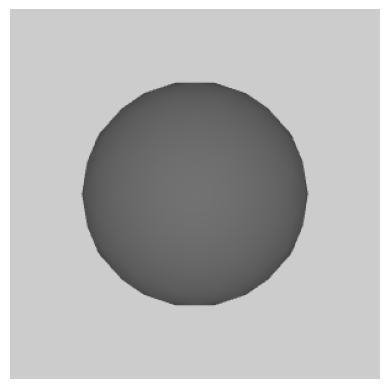

In [9]:
import os
# 最关键的一步：强制在导入 pyrender 之前设置后端
os.environ["PYOPENGL_PLATFORM"] = "egl"   # 也可以试试 "osmesa"

import numpy as np
import trimesh
import pyrender
import matplotlib.pyplot as plt

def test_simple():
    """创建一个简单的球体并渲染，检查是否产生非零图像"""
    # 创建球体网格
    sphere = trimesh.creation.icosphere(radius=0.5, subdivisions=2)
    mesh = pyrender.Mesh.from_trimesh(sphere)
    scene = pyrender.Scene(bg_color=[0.8, 0.8, 0.8, 1.0])
    scene.add(mesh)
    # 添加相机：距离 1.5，看向原点
    camera = pyrender.PerspectiveCamera(yfov=np.pi/3.0, aspectRatio=1.0)
    camera_pose = np.eye(4)
    camera_pose[2, 3] = 1.5   # z 轴方向 1.5
    scene.add(camera, pose=camera_pose)
    # 添加光源
    light = pyrender.DirectionalLight(color=[1.0,1.0,1.0], intensity=2.0)
    scene.add(light, pose=camera_pose)
    # 渲染
    r = pyrender.OffscreenRenderer(300, 300)
    color, depth = r.render(scene)
    r.delete()
    print("渲染图像 shape:", color.shape)
    print("像素值总和:", color.sum())
    # 显示图像（如果无 GUI 可以保存）
    plt.imshow(color)
    plt.axis('off')
    plt.savefig("/home/viplab/liukejia/project/result/render_test.png")
    print("测试图像已保存到 render_test.png")
    return color.sum() > 0

if __name__ == "__main__":
    success = test_simple()
    if success:
        print("✅ pyrender 工作正常！")
    else:
        print("❌ 渲染输出全黑，请检查环境配置。")